In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [15]:



df = pd.read_csv("vgsales.csv")

df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [16]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Shape: (16598, 11)

Column Names:
Index(['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales',
       'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  str    
 2   Platform      16598 non-null  str    
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  str    
 5   Publisher     16540 non-null  str    
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), str(4)
memory usage: 1.4 MB

Missing Values:
Rank              0
Name              0
Platf

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16598,16598,16327.000000,16598,16540,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
unique,NaN,11493,31,NaN,12,578,NaN,NaN,NaN,NaN,NaN
top,NaN,Need for Speed: Most Wanted,DS,NaN,Action,Electronic Arts,NaN,NaN,NaN,NaN,NaN
freq,NaN,12,2163,NaN,3316,1351,NaN,NaN,NaN,NaN,NaN
mean,8300.605254,NaN,NaN,2006.406443,NaN,NaN,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,NaN,NaN,5.828981,NaN,NaN,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,NaN,NaN,1980.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,NaN,NaN,2003.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,NaN,NaN,2007.000000,NaN,NaN,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,NaN,NaN,2010.000000,NaN,NaN,0.240000,0.110000,0.040000,0.040000,0.470000


In [17]:
df = df.drop_duplicates()

df = df.dropna()

print("Missing values after cleaning:")
print(df.isnull().sum())

print("Cleaned Dataset Shape:", df.shape)

Missing values after cleaning:
Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64
Cleaned Dataset Shape: (16291, 11)


In [18]:
df["Hit"] = (df["Global_Sales"] >= 1.0).astype(int)

print(df["Hit"].value_counts())

print("0 = Not Hit")
print("1 = Hit")

Hit
0    14233
1     2058
Name: count, dtype: int64
0 = Not Hit
1 = Hit


In [19]:
feature_names = [
    col for col in [
        "Platform",
        "Genre",
        "Publisher",
        "Year",
        "NA_Sales",
        "EU_Sales",
        "JP_Sales",
        "Other_Sales"
    ]
    if col in df.columns
]

X = df[feature_names].copy()
y = df["Hit"].copy()

print("Selected Features:")
print(feature_names)

display(X.head())

Selected Features:
['Platform', 'Genre', 'Publisher', 'Year', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']


,Platform,Genre,Publisher,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales
0,Wii,Sports,Nintendo,2006.0,41.49,29.02,3.77,8.46
1,NES,Platform,Nintendo,1985.0,29.08,3.58,6.81,0.77
2,Wii,Racing,Nintendo,2008.0,15.85,12.88,3.79,3.31
3,Wii,Sports,Nintendo,2009.0,15.75,11.01,3.28,2.96
4,GB,Role-Playing,Nintendo,1996.0,11.27,8.89,10.22,1.00


In [20]:
# Remove sales columns to avoid data leakage
X = df[feature_names].copy()

categorical_cols = X.select_dtypes(include=["object"]).columns

X = pd.get_dummies(X, columns=categorical_cols, dtype=int)

print("Converted Dataset:")
display(X.head())

print("Total Features:", len(X.columns))

C:\Users\Admin\AppData\Local\Temp\ipykernel_16232\2786483046.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=["object"]).columns


Converted Dataset:


,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Platform_2600,Platform_3DO,Platform_3DS,Platform_DC,Platform_DS,...,Publisher_Zushi Games,Publisher_bitComposer Games,Publisher_dramatic create,Publisher_fonfun,Publisher_iWin,Publisher_id Software,Publisher_imageepoch Inc.,Publisher_inXile Entertainment,"Publisher_mixi, Inc",Publisher_responDESIGN
0,2006.0,41.49,29.02,3.77,8.46,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1985.0,29.08,3.58,6.81,0.77,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2008.0,15.85,12.88,3.79,3.31,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2009.0,15.75,11.01,3.28,2.96,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1996.0,11.27,8.89,10.22,1.00,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Total Features: 624


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (13032, 624)
Testing Data: (3259, 624)


In [22]:
model = DecisionTreeClassifier(
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model trained successfully!")

Model trained successfully!



Model: Default Model
Accuracy: 0.991
Precision: 0.973
Recall: 0.954
F1 Score: 0.963

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      2847
           1       0.97      0.95      0.96       412

    accuracy                           0.99      3259
   macro avg       0.98      0.98      0.98      3259
weighted avg       0.99      0.99      0.99      3259



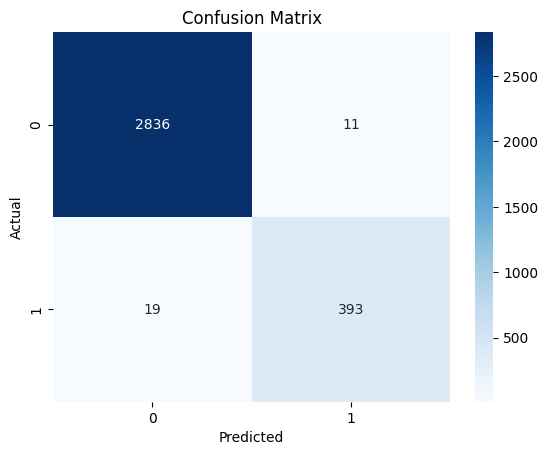

In [23]:
def evaluate(name, model, show=True):

    pred = model.predict(X_test)

    acc = accuracy_score(y_test, pred)

    precision = precision_score(
        y_test, pred, zero_division=0
    )

    recall = recall_score(
        y_test, pred, zero_division=0
    )

    f1 = f1_score(
        y_test, pred, zero_division=0
    )

    result = {
        "Setting": name,
        "Accuracy": acc,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    }

    if show:
        print("\nModel:", name)
        print("Accuracy:", round(acc, 3))
        print("Precision:", round(precision, 3))
        print("Recall:", round(recall, 3))
        print("F1 Score:", round(f1, 3))

        print("\nClassification Report:")
        print(classification_report(
            y_test, pred, zero_division=0
        ))

        cm = confusion_matrix(y_test, pred)

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues"
        )

        plt.title("Confusion Matrix")
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.show()

    return result


results = []

results.append(evaluate("Default Model", model))

In [24]:
settings = [
    {"max_depth": 3, "criterion": "gini"},
    {"max_depth": 5, "criterion": "gini"},
    {"max_depth": 8, "criterion": "gini"},
    {"max_depth": 10, "criterion": "entropy"},
    {"max_depth": None, "criterion": "entropy"}
]

for s in settings:

    temp_model = DecisionTreeClassifier(
        max_depth=s["max_depth"],
        criterion=s["criterion"],
        random_state=42
    )

    temp_model.fit(X_train, y_train)

    name = f"Depth={s['max_depth']}, {s['criterion']}"

    results.append(
        evaluate(name, temp_model, show=False)
    )

print("All settings tested successfully!")

All settings tested successfully!


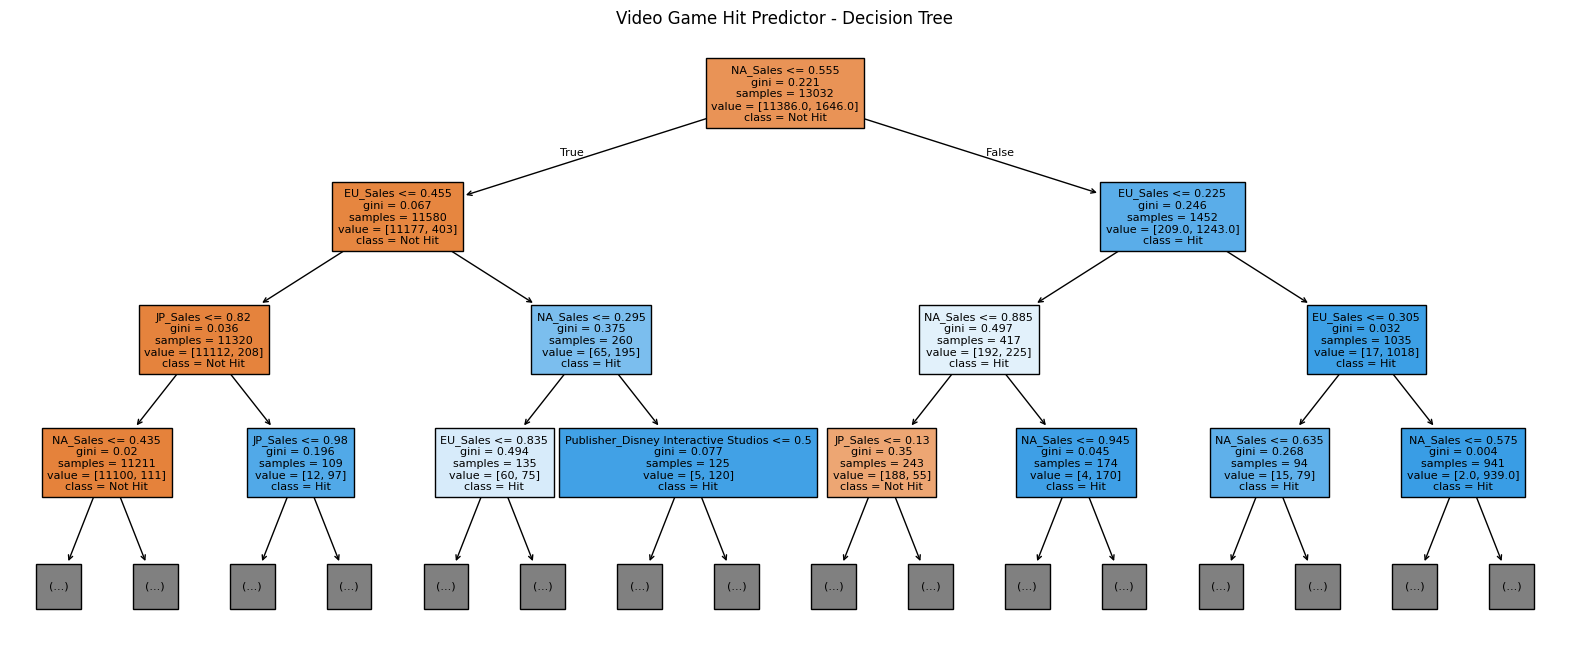

In [25]:
best_depth = 5

tree = DecisionTreeClassifier(
    max_depth=best_depth,
    random_state=42
)

tree.fit(X_train, y_train)

plt.figure(figsize=(20, 8))

plot_tree(
    tree,
    max_depth=3,
    feature_names=[str(f) for f in X_train.columns],
    class_names=["Not Hit", "Hit"],
    filled=True,
    fontsize=8
)

plt.title("Video Game Hit Predictor - Decision Tree")
plt.show()

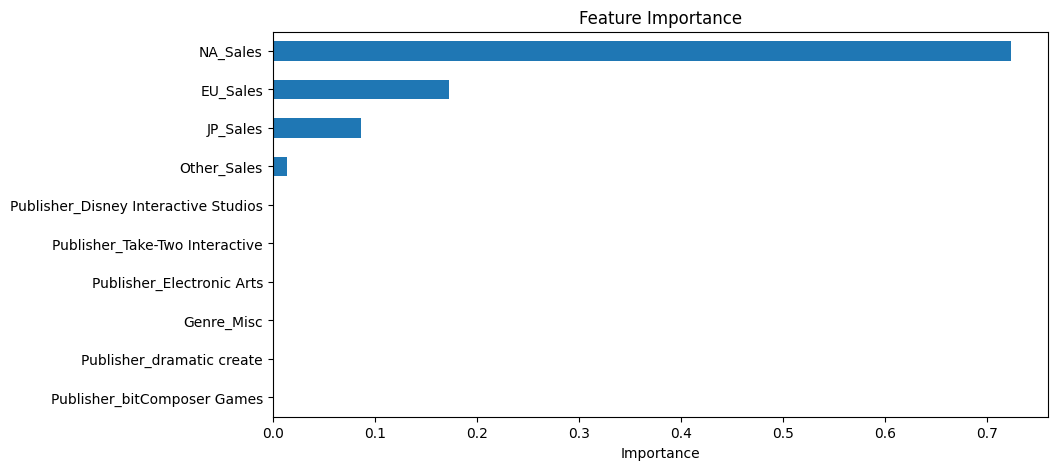

In [26]:
importance = pd.Series(
    tree.feature_importances_,
    index=X_train.columns
).sort_values().tail(10)

importance.plot(kind="barh", figsize=(10, 5))

plt.title("Feature Importance")
plt.xlabel("Importance")
plt.show()

,Setting,Accuracy,Precision,Recall,F1
0,Default Model,0.991,0.973,0.954,0.963
1,"Depth=3, gini",0.977,0.940,0.876,0.907
2,"Depth=5, gini",0.985,0.974,0.908,0.940
3,"Depth=8, gini",0.990,0.966,0.951,0.958
4,"Depth=10, entropy",0.989,0.965,0.949,0.957
5,"Depth=None, entropy",0.990,0.966,0.951,0.958


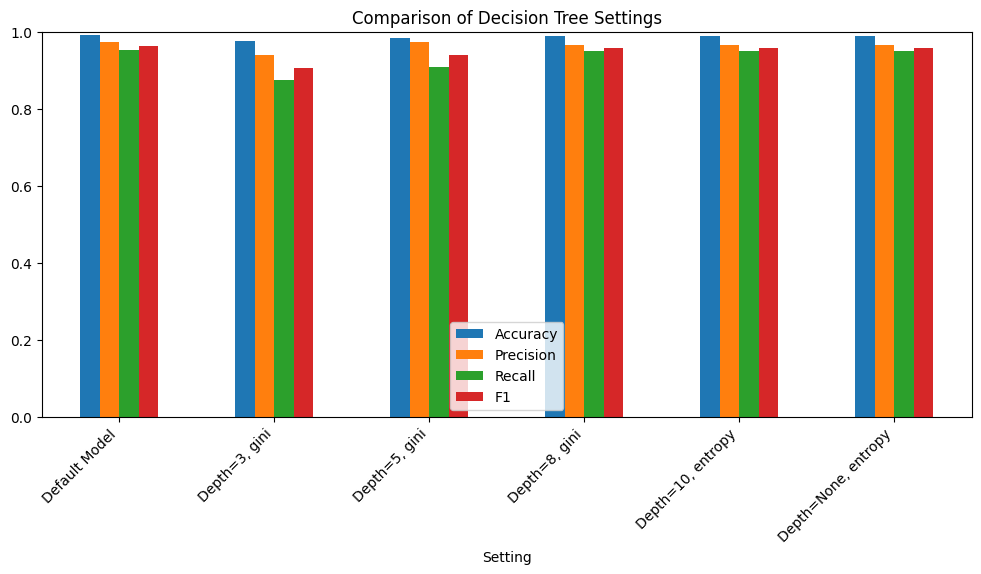

Best Setting: Depth=5, gini
Best Precision: 0.974


In [27]:
res = pd.DataFrame(results).round(3)

display(res)

res.set_index("Setting")[
    ["Accuracy", "Precision", "Recall", "F1"]
].plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Comparison of Decision Tree Settings")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.show()

best = res.iloc[
    res["Precision"].argmax()
]

print("Best Setting:", best["Setting"])
print("Best Precision:", best["Precision"])


Model: FINAL MODEL
Accuracy: 0.985
Precision: 0.974
Recall: 0.908
F1 Score: 0.94

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      2847
           1       0.97      0.91      0.94       412

    accuracy                           0.99      3259
   macro avg       0.98      0.95      0.97      3259
weighted avg       0.99      0.99      0.99      3259



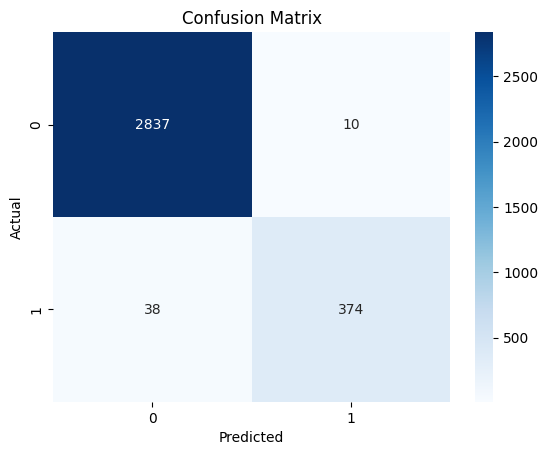

{'Setting': 'FINAL MODEL',
 'Accuracy': 0.98527155569193,
 'Precision': 0.9739583333333334,
 'Recall': 0.9077669902912622,
 'F1': 0.9396984924623115}

In [28]:
best_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# Train final model
best_model.fit(X_train, y_train)

# Evaluate final model
final_model = best_model

evaluate("FINAL MODEL", final_model, show=True)

In [29]:
new = X.iloc[[0, 1, 2]].copy()

if "Year" in new.columns:
    new["Year"] = new["Year"] + 1

display(new)

pred = final_model.predict(new)

labels = ["Not Hit", "Hit"]

print("\nPredictions:")

for i, p in enumerate(pred):
    print(f"Game {i+1}: {labels[p]}")

,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Platform_2600,Platform_3DO,Platform_3DS,Platform_DC,Platform_DS,...,Publisher_Zushi Games,Publisher_bitComposer Games,Publisher_dramatic create,Publisher_fonfun,Publisher_iWin,Publisher_id Software,Publisher_imageepoch Inc.,Publisher_inXile Entertainment,"Publisher_mixi, Inc",Publisher_responDESIGN
0,2007.0,41.49,29.02,3.77,8.46,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1986.0,29.08,3.58,6.81,0.77,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2009.0,15.85,12.88,3.79,3.31,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Predictions:
Game 1: Hit
Game 2: Hit
Game 3: Hit


In [30]:
new = X.iloc[[0, 1, 2]].copy()

if "Year" in new.columns:
    new["Year"] = new["Year"] + 1

display(new)

pred = final_model.predict(new)

labels = ["Not Hit", "Hit"]

print("\nPredictions:")

for i, p in enumerate(pred):
    print(f"Game {i+1}: {labels[p]}")

,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Platform_2600,Platform_3DO,Platform_3DS,Platform_DC,Platform_DS,...,Publisher_Zushi Games,Publisher_bitComposer Games,Publisher_dramatic create,Publisher_fonfun,Publisher_iWin,Publisher_id Software,Publisher_imageepoch Inc.,Publisher_inXile Entertainment,"Publisher_mixi, Inc",Publisher_responDESIGN
0,2007.0,41.49,29.02,3.77,8.46,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1986.0,29.08,3.58,6.81,0.77,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2009.0,15.85,12.88,3.79,3.31,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Predictions:
Game 1: Hit
Game 2: Hit
Game 3: Hit
